---
tags: [algorithm, optimization, variational]
---

# QAOA によるグラフ分割

本チュートリアルでは、Quantum Approximate Optimization Algorithm（QAOA）を用いて**グラフ分割問題**を解く方法を紹介します。

ワークフロー：

```
JijModeling 問題定義 → problem.eval() → QAOAConverter → transpile → sample → decode
```

1. [JijModeling](https://jij-inc-jijmodeling-tutorials-ja.readthedocs-hosted.com/ja/latest/introduction.html) で問題を定式化する。
2. 具体的なデータでインスタンスを作成する。
3. `QAOAConverter` を使って QAOA 回路とハミルトニアンを構築する。
4. 古典オプティマイザで変分パラメータを最適化する。
5. 最適化された回路をサンプリングし、結果をデコードする。


## インストール

```bash
pip install "qamomile[qiskit,visualization]" jijmodeling
```

In [1]:
# Install the latest Qamomile and JijModeling through pip!
# !pip install "qamomile[qiskit,visualization]" jijmodeling

In [2]:
import os

import jijmodeling as jm
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
from scipy.optimize import minimize

import qamomile as qm
from qamomile.optimization import BinaryModel, OMMXProblem, QAOAExperiment, VarType
from qamomile.qiskit import Qiskit, load_circuit

docs_test_mode = os.environ.get("QAMOMILE_DOCS_TEST") == "1"

## 問題の定式化

無向グラフ $G = (V, E)$ が与えられたとき、頂点を同じサイズの 2 つのグループに分割し、グループ間のエッジ数を最小化することが目標です。

**目的関数：**

$$
\min \sum_{(u,v) \in E} \bigl[x_u(1 - x_v) + x_v(1 - x_u)\bigr]
$$

**制約条件：**

$$
\sum_{u \in V} x_u = \frac{|V|}{2}
$$

ここで $x_u \in \{0, 1\}$ は頂点 $u$ がどちらのグループに属するかを表します。

## JijModeling による問題定義


In [3]:
formulation = jm.Problem("Graph Partitioning")


@formulation.update
def _(problem: jm.DecoratedProblem):
    vertices = problem.Dim()
    edges = problem.Natural(ndim=2)
    x = problem.BinaryVar(shape=(vertices,))

    problem += (
        edges.rows()
        .map(lambda edge: x[edge[0]] * (1 - x[edge[1]]) + x[edge[1]] * (1 - x[edge[0]]))
        .sum()
    )
    problem += problem.Constraint("Equal Partition", x.sum() == vertices / 2)


formulation

Problem(name="Graph Partitioning", sense=MINIMIZE, objective=sum(edges.rows().map(lambda (edge: Array[:; natural]): x[edge[0]] * (1 - x[edge[1]]) + x[edge[1]] * (1 - x[edge[0]]))), constraints={Equal Partition: [Constraint(name="Equal Partition", sense=EQUAL, left=sum(x), right=vertices / 2, shape=Scalar(Float)),],})

## グラフインスタンス

再現性を確保するため、8 ノード 16 エッジの固定グラフを使用します。


In [4]:
NUM_NODES = 8
EDGE_LIST = (
    (0, 2),
    (0, 3),
    (0, 4),
    (1, 2),
    (1, 3),
    (1, 4),
    (1, 5),
    (1, 7),
    (2, 3),
    (2, 6),
    (3, 5),
    (4, 5),
    (4, 6),
    (5, 6),
    (5, 7),
    (6, 7),
)

graph = nx.Graph()
graph.add_nodes_from(range(NUM_NODES))
graph.add_edges_from(EDGE_LIST)
positions = nx.spring_layout(graph, seed=1)

assert graph.number_of_nodes() == NUM_NODES
assert graph.number_of_edges() == len(EDGE_LIST) == 16

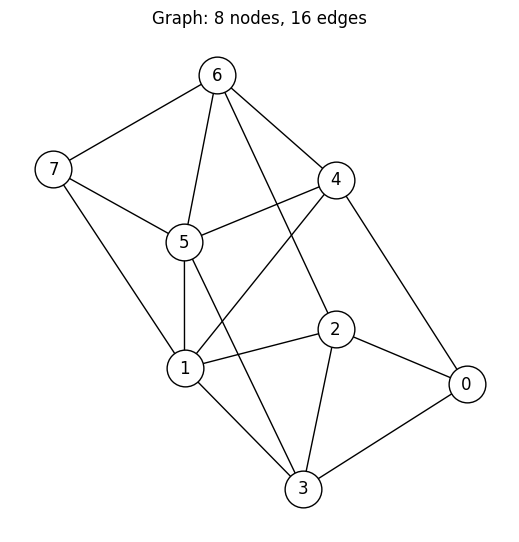

In [5]:
plt.figure(figsize=(5, 5))
nx.draw(
    graph,
    positions,
    with_labels=True,
    node_color="white",
    node_size=700,
    edgecolors="black",
)
plt.title(f"Graph: {graph.number_of_nodes()} nodes, {graph.number_of_edges()} edges")
plt.show()

## InstanceとPenalty Modelを作る

`OMMXProblem.from_instance`はcallerのinstanceをcopyし、equal-partition constraintを
binary penalty modelへ取り込み、sampling後の評価用に元のbytesを保持します。
caller-owned instanceは変更しません。penalty energyは最適化だけに使い、feasibilityと
cut数は常に元のOMMX instanceから得ます。

In [6]:
instance = formulation.eval(
    {
        "vertices": NUM_NODES,
        "edges": [list(edge) for edge in EDGE_LIST],
    }
)
original_payload = instance.to_bytes()
problem = OMMXProblem.from_instance(instance, uniform_penalty_weight=16.0)

assert instance.to_bytes() == original_payload
assert problem.model.vartype is VarType.BINARY
assert problem.model.num_variables == NUM_NODES
assert problem.model.order == 2
assert BinaryModel.from_bytes(problem.model.to_bytes()) == problem.model

print(f"Penalty terms: {len(problem.model.coefficients)}")
print(f"QAOA Hamiltonian terms: {len(problem.model.hamiltonian.terms)}")

Penalty terms: 36
QAOA Hamiltonian terms: 28


## QAOA Experimentを構築・Compileする

通常実行では元と同じ5層のQAOAを使います。documentation testでは1層ですが、
compilation、optimizer、sampling、OMMX evaluationの経路は同じです。固定長の
`gammas`と`betas`だけがruntime ABIに残り、全optimizer候補が1つのartifactを
再利用します。

In [7]:
LAYERS = 1 if docs_test_mode else 5
experiment = QAOAExperiment(problem.model, layers=LAYERS)
endpoint = qm.Reference()
compiled = experiment.compile(to=endpoint.target)

assert tuple(slot.name for slot in compiled.artifact.parameter_abi.slots) == (
    "gammas",
    "betas",
)
assert compiled.identity == experiment.identity
assert compiled.identity.problem_digest == problem.model.semantic_digest
assert "quantum.qaoa" not in experiment.program.inspect()

## Circuitを可視化し、Building Blockを確認する

QAOAは通常のcompositionです。各量子ビットへの最初のHadamardに続き、cost evolution
とX-mixer rotationを交互に適用します。2層のQiskit projectionにより、mutableな
compiler-pass APIを公開せず、繰り返す`rzz`/`rz` cost realizationと`rx` mixerを
確認できます。

global phase: (-40)*p0 - 40*p1
     ┌───┐                                                                                                            »
q_0: ┤ H ├─■───────────■───────────■───────────────────────■───────────────────────■──────────────────────────────────»
     ├───┤ │ZZ(16*p0)  │           │                       │                       │                                  »
q_1: ┤ H ├─■───────────┼───────────┼───────────■───────────┼───────────■───────────┼───────────■──────────────────────»
     ├───┤             │ZZ(15*p0)  │           │ZZ(15*p0)  │           │           │           │                      »
q_2: ┤ H ├─────────────■───────────┼───────────■───────────┼───────────┼───────────┼───────────┼───────────■──────────»
     ├───┤                         │ZZ(15*p0)              │           │ZZ(15*p0)  │           │           │ZZ(15*p0) »
q_3: ┤ H ├─────────────────────────■───────────────────────┼───────────■───────────┼───────────┼───────────■──────────»
     ├───

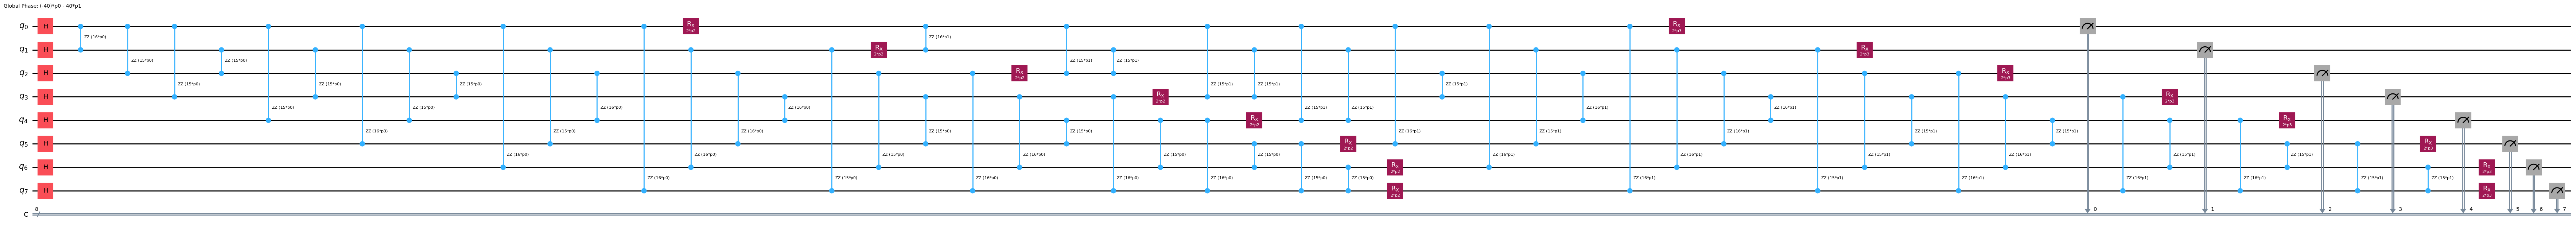

In [8]:
visualization_experiment = QAOAExperiment(problem.model, layers=2)
visualization_artifact = qm.compile(visualization_experiment.program, to=Qiskit())
visualization_circuit = load_circuit(visualization_artifact)

print(visualization_circuit.draw(output="text", fold=120))
print("Circuit operations:", dict(visualization_circuit.count_ops()))
visualization_circuit.draw(output="mpl", fold=-1)

resource解析は同じcomposed bodyを参照します。`LAYERS`層なら、problem qubitごとに
1つのHadamard、cost layerごとに1つのabstract Pauli evolution、各qubit・各層に
1つのRX mixer rotationを数えます。

In [9]:
study = qm.resources.logical(experiment.program)

assert study.metric(
    qm.resources.logical_operation_count("quantum.h")
).numeric_enclosure() == (NUM_NODES, NUM_NODES)
assert study.metric(
    qm.resources.logical_operation_count("quantum.rx")
).numeric_enclosure() == (NUM_NODES * LAYERS, NUM_NODES * LAYERS)
assert study.metric(
    qm.resources.logical_operation_count("quantum.pauli_evolution")
).numeric_enclosure() == (LAYERS, LAYERS)

## QAOA Parameterを最適化する

COBYLAはsamplingしたQAOA runが返すoccurrence-weighted penalty energyを最小化します。
ここでunpenalizedなcut objectiveを使うと、infeasibleなall-zero/all-one assignmentを
許すため不適切です。通常実行は元と同じ1,000候補のoptimizerを保ち、Reference
endpointのlaunch単位のwork guard内に収めるため各launchを256 shotsにします。
documentation testでは両方のbudgetを短縮します。

In [10]:
SAMPLE_SHOTS = 16 if docs_test_mode else 256
MAX_ITERATIONS = 6 if docs_test_mode else 1_000
FINAL_SHOTS = 128 if docs_test_mode else 256
cost_history = []


def cost_function(parameters) -> float:
    """Sample one QAOA coordinate and return its mean penalty energy."""

    run = compiled.run(
        on=endpoint,
        gammas=tuple(float(value) for value in parameters[:LAYERS]),
        betas=tuple(float(value) for value in parameters[LAYERS:]),
        shots=SAMPLE_SHOTS,
        seed=901 + len(cost_history),
    )
    cost_history.append(run.samples.mean_energy)
    return run.samples.mean_energy


rng = np.random.default_rng(900)
initial_parameters = rng.uniform(0.0, np.pi, 2 * LAYERS)
optimization = minimize(
    cost_function,
    initial_parameters,
    method="COBYLA",
    options={"maxiter": MAX_ITERATIONS, "rhobeg": 0.5},
)

print(f"Optimized penalty cost: {optimization.fun:+.6f}")
print(f"Function evaluations: {optimization.nfev}")
assert len(optimization.x) == 2 * LAYERS
assert len(cost_history) == optimization.nfev

Optimized penalty cost: +27.847656
Function evaluations: 83


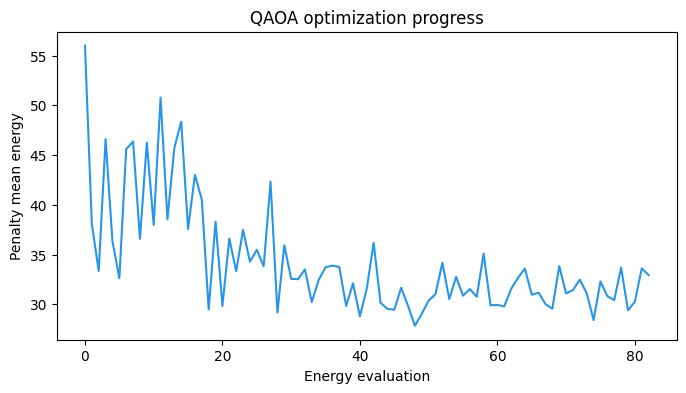

In [11]:
plt.figure(figsize=(8, 4))
plt.plot(cost_history, color="#2696EB")
plt.xlabel("Energy evaluation")
plt.ylabel("Penalty mean energy")
plt.title("QAOA optimization progress")
plt.show()

## 最適化したParameterでSampleする

最後により大きいrunでcandidate partitionを集めます。decoded distributionは、
`problem.evaluate`が変更していない元のOMMX instanceへfeasibility、constraint診断、
true objectiveを問い合わせるまで、penalty modelのBINARY domainに留まります。

In [12]:
optimized_run = compiled.run(
    on=endpoint,
    gammas=tuple(float(value) for value in optimization.x[:LAYERS]),
    betas=tuple(float(value) for value in optimization.x[LAYERS:]),
    shots=FINAL_SHOTS,
    seed=1901,
)
evaluation = problem.evaluate(optimized_run.samples)

feasible_shots = sum(
    evaluation.occurrences[sample_id]
    for sample_id, feasible in evaluation.feasible.items()
    if feasible
)

print(
    f"Feasible samples: {feasible_shots} / {FINAL_SHOTS} "
    f"({100.0 * feasible_shots / FINAL_SHOTS:.1f}%)"
)

assert optimized_run.execution.artifact is compiled.artifact
assert optimized_run.samples.total_occurrences == FINAL_SHOTS
assert evaluation.total_occurrences == FINAL_SHOTS
assert feasible_shots > 0

Feasible samples: 84 / 256 (32.8%)


## 結果を解析する

### 最良のFeasible Solution

`best_feasible`はfeasibleなunique rowのうち、元のcut objectiveが最小のものを返します。
decision-variable値は元のIDを使い、equality constraintを直接確認できます。

In [13]:
best = evaluation.best_feasible
values = best.decision_variables_df["value"]
best_assignment = {
    index: int(round(float(values.loc[index]))) for index in range(NUM_NODES)
}
best_objective = int(round(best.objective))
cut_edges = sum(
    best_assignment[left] != best_assignment[right] for left, right in EDGE_LIST
)

print("Best feasible partition:", best_assignment)
print(f"Cut edges: {best_objective}")

assert sum(best_assignment.values()) == NUM_NODES // 2
assert best_objective == cut_edges
assert best_objective >= 0

Best feasible partition: {0: 0, 1: 0, 2: 0, 3: 0, 4: 1, 5: 1, 6: 1, 7: 1}
Cut edges: 6


### Objective Valueの分布

immutable evaluationはunique solutionごとのrowと元のoccurrence countを保持します。
feasibleなoccurrenceを元のobjectiveでgroup化し、duplicate rowを展開せずshot-levelの
histogramを再現します。

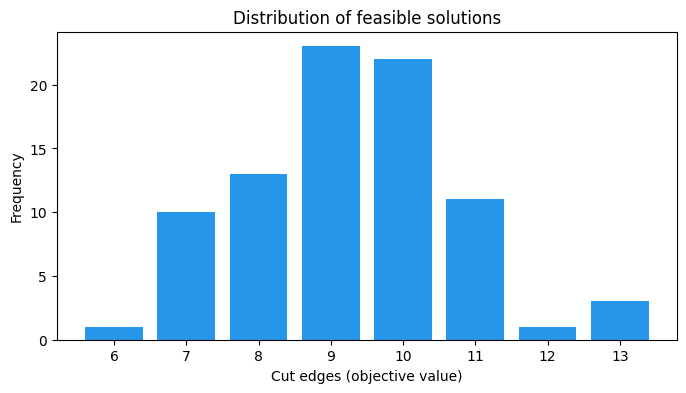

In [14]:
objective_counts = {}
for sample_id in evaluation.sample_ids:
    if not evaluation.feasible[sample_id]:
        continue
    objective = int(round(evaluation.objectives[sample_id]))
    objective_counts[objective] = (
        objective_counts.get(objective, 0) + evaluation.occurrences[sample_id]
    )

assert sum(objective_counts.values()) == feasible_shots

plt.figure(figsize=(8, 4))
plt.bar(
    [str(value) for value in sorted(objective_counts)],
    [objective_counts[value] for value in sorted(objective_counts)],
    color="#2696EB",
)
plt.xlabel("Cut edges (objective value)")
plt.ylabel("Frequency")
plt.title("Distribution of feasible solutions")
plt.show()

### 最良Partitionを可視化する

nodeの色で、最良のfeasible QAOA sampleが与える2つの等しいgroupを示します。

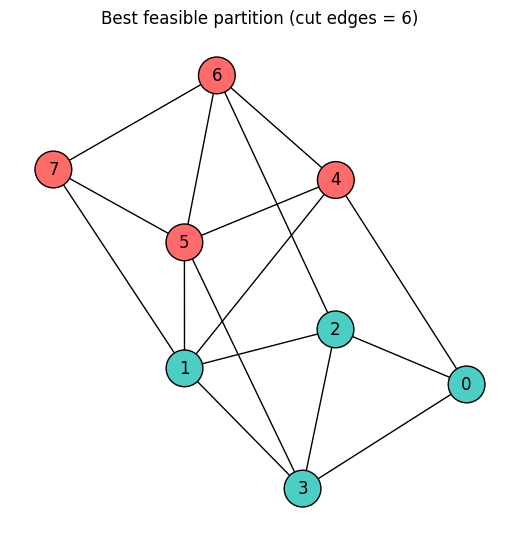

In [15]:
colors = [
    "#FF6B6B" if best_assignment[index] == 1 else "#4ECDC4"
    for index in range(NUM_NODES)
]
plt.figure(figsize=(5, 5))
nx.draw(
    graph,
    positions,
    with_labels=True,
    node_color=colors,
    node_size=700,
    edgecolors="black",
)
plt.title(f"Best feasible partition (cut edges = {best_objective})")
plt.show()

## まとめ

- 元の8-node制約付きJijModeling instanceを保ちます。
- 5層QAOA programを一度compileし、penalty-domain mean energyで連続最適化します。
- 完全なcircuit可視化とlogical resourceにより、Hadamard、cost、mixerのbuilding
  blockを確認します。
- 最終samplingではpenalty energyとapplicationの意味を混同せず、元のOMMX
  feasibility、best objective、objective分布、graph partitionを得ます。